In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

In [3]:
# Step 1: Load the dataset
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
print("Missing ages:", df["Age"].isnull().sum())
print("Survival counts:\n", df["Survived"].value_counts())

Dataset shape: (891, 11)
Missing ages: 177
Survival counts:
 Survived
0    549
1    342
Name: count, dtype: int64


In [4]:
# Step 2: Select features and target
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
X = df[features].copy()
y = df["Survived"]


In [5]:
# Encode categorical values
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

In [6]:
# Step 3: Divide the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
# Step 4: Handle missing ages
median_age = X_train["Age"].median()
X_train = X_train.fillna({"Age": median_age})
X_test = X_test.fillna({"Age": median_age})

In [8]:
print("Median age:", median_age)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Median age: 28.5
Training records: 712
Testing records: 179


In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [10]:
# Step 6: Make predictions
y_pred = rf_model.predict(X_test)

In [11]:
# Step 7: Evaluate predictions
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nRANDOM FOREST RESULTS")
print(f"Accuracy : {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall   : {recall:.2%}")
print(f"F1-score : {f1:.2%}")


RANDOM FOREST RESULTS
Accuracy : 81.01%
Precision: 77.78%
Recall   : 71.01%
F1-score : 74.24%


In [12]:
print("\nConfusion matrix:\n", cm)
print("\nClassification report:\n",
      classification_report(y_test, y_pred))


Confusion matrix:
 [[96 14]
 [20 49]]

Classification report:
               precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



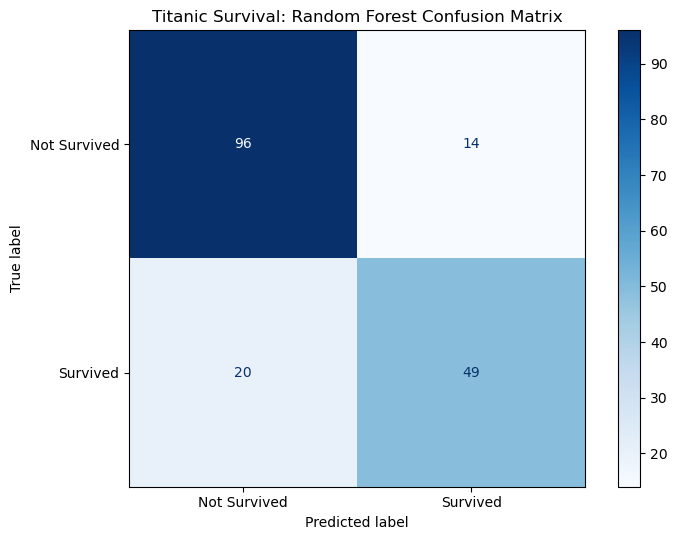

In [14]:
# Step 8: Plot confusion matrix
fig, ax = plt.subplots(figsize=(7.5, 5.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues", ax=ax, values_format="d"
)

ax.set_title("Titanic Survival: Random Forest Confusion Matrix")
fig.tight_layout()
plt.show()

In [19]:
# Step 9: Plot feature importance
importance = pd.Series(rf_model.feature_importances_, index=features)
importance = importance.sort_values(ascending=True)

In [20]:
importance.head(10)

Parch     0.037910
SibSp     0.048162
Pclass    0.084377
Age       0.258304
Sex       0.263365
Fare      0.307882
dtype: float64

In [21]:
# Step 10: Display individual predictions
sample_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "P(Survived)": rf_model.predict_proba(X_test)[:, 1]
})

print("\nFirst 10 test-set predictions:")
print(sample_results.head(10).round(3).to_string(index=False))



First 10 test-set predictions:
 Actual  Predicted  P(Survived)
      0          0        0.360
      0          0        0.190
      1          0        0.060
      0          0        0.025
      1          1        0.840
      1          0        0.270
      1          1        0.790
      0          1        0.850
      0          0        0.480
      0          0        0.270
